# ViZDoom Deadly Corridor: DQN with AgileRL

In this notebook, we're going to train a Double DQN agent to beat the Deadly Corridor scenario in ViZDoom, using only visual observations from the game!

This notebook won't be going over the specifics of DQN or RL as a whole, more just how to use AgileRL for a Double DQN run on Deadly Corridor.

We'll be using the AgileRL library for our DQN implementation. AgileRL is built for population-based training, but a single agent works just as well, and it's easy to pick up and extend. It ships with DQN, Rainbow, and PPO, and in my experience it converges faster than Stable Baselines3 in experiments like this one. That makes it perfect for quick tests!

Deadly Corridor is a big step up from Basic: a long hallway lined with enemies, and a vest waiting at the far end, with the goal of having Doomguy fight his way to it! And he has to fight, if he just tries to run for it he'll get gunned down! The official writeup of the scenario is [here](https://vizdoom.farama.org/environments/default/#deadly-corridor).

One twist: training uses the stock scenario, but evaluation and recording use `deadly_corridor_outro`, a version I made so the episode doesn't end the instant Doomguy grabs the vest or dies. This lets the ending play out, including the death animation if he didn't make it, instead of cutting straight to black. This is optional however, and the notebook should be robust enough so that it doesn't crash if it can't find it.

Similarly it also tries to use the original Doom WADs if it can find them.

The notebook was designed to run in place in the repo, however it also supports running on Google Colab, with the option of using Google Drive to save artifacts.


# Setup
First, we'll install the dependencies and load the imports.

Install the pinned dependencies first.

In [1]:
import sys

# Update the required system packages when running on Colab.
if "google.colab" in sys.modules:
    !apt-get update -qq
    !apt-get install -y -qq libopenal1 libopenal-dev > /dev/null

# Install the Python packages used throughout the notebook.
%pip install -q vizdoom==1.3.1 agilerl==2.8.4 gymnasium==1.3.0 imageio==2.38.0 imageio-ffmpeg==0.6.0 opencv-python==5.0.0.93 scipy==1.17.1 numpy==2.4.6 pandas==3.0.5 torch==2.13.0 matplotlib==3.11.1


Note: you may need to restart the kernel to use updated packages.


# Imports
Next, import everything used throughout the notebook.

In [2]:
import json
import os
import shutil
import subprocess
import sys
from datetime import datetime
from pathlib import Path

import gymnasium
import imageio.v2 as imageio
import imageio_ffmpeg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch


from agilerl.algorithms.dqn import DQN
from agilerl.components.replay_buffer import ReplayBuffer
from agilerl.training.train_off_policy import train_off_policy
from gymnasium.spaces import Box
from gymnasium.wrappers import FrameStackObservation, ResizeObservation, TransformObservation, TransformReward
from IPython.display import Image, display
from scipy.io import wavfile


import vizdoom as vzd
from vizdoom import gymnasium_wrapper  # registers the Vizdoom* gymnasium envs
from vizdoom.gymnasium_wrapper.base_gymnasium_env import VizdoomEnv

/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Experiment Setup
The experiment uses a DQN-on-pixels setup. The agent acts every 4 frames and sees the last 4 frames stacked at 84x84, which gives it a sense of motion. Deadly Corridor has 7 buttons, and we allow up to 3 at once, so the agent can move, turn, and shoot together. That comes out to 64 actions, a big jump from Basic's 4. Episodes are long, so we run 16 environments side by side.

`KILL_BONUS` and `DAMAGE_PENALTY` control the reward shaping. `EVAL_EPISODES` is how many episodes we use to score each checkpoint. `RECORD_EPISODES` is how many videos we save. Set `RECORD_CHECKPOINTS` to `"all"` if you want every generation, although converting all of them takes a while.

In [3]:
ENV_NAME = "VizdoomDeadlyCorridor-v1"
NUM_ENVS = 16
FRAME_SKIP = 4          # act every 4 frames
STACK_SIZE = 4          # last 4 frames, so the agent can see motion
OBS_SIZE = (84, 84)
MAX_BUTTONS_PRESSED = 3 # up to 3 buttons at once
KILL_BONUS = 1.0       # reward per kill
DAMAGE_PENALTY = 0.03  # penalty per point of health lost

EVAL_EPISODES = 4
RECORD_EPISODES = 3
RECORD_CHECKPOINTS = "best"  # or "all"


All the path logic lives in the next few cells, so the rest of the notebook doesn't need to care whether it's running on Colab or locally.

On Colab, `USE_DRIVE` keeps the run in Google Drive so it survives the session. Otherwise, everything stays in the notebook's folder.

In [4]:
USE_DRIVE = True # Colab only: keep the experiment (and every output) in Google Drive
EXPERIMENT = "deadly-corridor-dqn-AgileRL"

if "google.colab" in sys.modules and USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    experiment_dir = Path("/content/drive/MyDrive/rl-epsilon/vizdoom-agilerl-experiments") / EXPERIMENT
elif "google.colab" in sys.modules:
    experiment_dir = Path("/content") / EXPERIMENT  # lost when the Colab session ends
else:
    experiment_dir = Path.cwd()  # local: the notebook's own folder
print("experiment:", experiment_dir)


experiment: /Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/deadly-corridor-dqn-AgileRL


ViZDoom ships with Freedoom. But if `DOOM2.WAD` is in the `WADS` folder, we use that instead. Always better to use the original assets in my opinion! The scenario follows the same fallback pattern: `deadly_corridor_outro` lets the ending play out, but if that file isn't available, we use the stock scenario.

In [5]:
USE_DOOM2_WAD = True  # use DOOM2.WAD if found, otherwise ViZDoom's bundled Freedoom
SCENARIO = "deadly_corridor_outro.cfg"   # custom scenario in scenario_files/
STOCK_SCENARIO = "deadly_corridor.cfg"  # bundled with ViZDoom, used if the custom one is missing

custom_cfg = experiment_dir / "scenario_files" / SCENARIO
scenario_cfg = str(custom_cfg if custom_cfg.is_file() else Path(vzd.scenarios_path) / STOCK_SCENARIO)
SCENARIO_NAME = Path(scenario_cfg).stem

wad = experiment_dir.parent / "WADS" / "DOOM2.WAD"
DOOM_WAD = str(wad) if USE_DOOM2_WAD and wad.is_file() else None
IWAD_NAME = Path(DOOM_WAD).name if DOOM_WAD else "freedoom2"
print("scenario:", scenario_cfg)
print("IWAD:", IWAD_NAME)

scenario: /Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/deadly-corridor-dqn-AgileRL/scenario_files/deadly_corridor_outro.cfg
IWAD: DOOM2.WAD


Each run gets its own timestamped folder. The best model, charts, and videos are copied to `artifacts`.

In [6]:
run_dir = experiment_dir / "training-runs" / f"run-{datetime.now():%Y%m%d_%H%M%S}"
checkpoint_dir = run_dir / "checkpoints"
recording_dir = run_dir / "recordings"
artifacts_dir = experiment_dir / "artifacts"
model_dir = artifacts_dir / "model"
video_dir = artifacts_dir / "video"
figure_dir = artifacts_dir / "plots_and_figures"
for d in (checkpoint_dir, recording_dir, model_dir, video_dir, figure_dir):
    d.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "DQN.pt"
best_model_path = model_dir / "best_model.pt"
metrics_csv = figure_dir / "generation_metrics.csv"
results_path = artifacts_dir / "results.json"
print("run:", run_dir.name)

run: run-20261020_162823


# Environment
Next, we'll build the environment used to train Doomguy.

Deadly Corridor puts him at one end of a long hallway with a vest at the other. Enemies line both sides, and the scenario runs on the hardest skill, so running straight for the vest usually gets him killed. He can move in every direction, turn, and fire. The agent only sees the first-person view.

The stock reward is mostly about distance: moving toward the vest pays, moving away costs, the vest is worth +1000, dying costs 100, and the episode times out after 2100 tics. Because that reward mostly says "go forward," it's easy to learn a policy that sprints and dies. `RewardWrapper` adds `KILL_BONUS` for every kill and subtracts `DAMAGE_PENALTY` for every point of health lost, using the kill count and health straight from the game.

`RewardWrapper` applies that shaping after the reward has already been scaled, so a kill is worth about as much as 100 units of the stock reward.

In [7]:
class RewardWrapper(gymnasium.Wrapper):
    """Adds KILL_BONUS per kill and subtracts DAMAGE_PENALTY per point of health lost."""

    def _read(self):
        game = self.env.unwrapped.game
        return game.get_game_variable(vzd.GameVariable.KILLCOUNT), game.get_game_variable(vzd.GameVariable.HEALTH)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.kills, self.health = self._read()
        return obs, info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        kills, health = self._read()
        reward += KILL_BONUS * max(0, kills - self.kills) - DAMAGE_PENALTY * max(0, self.health - health)
        self.kills, self.health = kills, health
        return obs, reward, terminated, truncated, info

`preprocess_env` turns each frame into an 84x84 grayscale image, stacks the last 4, and divides the reward by 100. The vest is then worth about 10 instead of 1000, which keeps the Q-values in a friendlier range. The shaping gets added on top.

In [8]:
def preprocess_env(env):
    h, w, _ = env.observation_space["screen"].shape
    env = TransformObservation(
        env,
        lambda obs: (obs["screen"] @ np.array([0.299, 0.587, 0.114])).astype(np.uint8),
        Box(low=0, high=255, shape=(h, w), dtype=np.uint8),
    )  # grayscale
    env = ResizeObservation(env, OBS_SIZE)  # 84x84
    env = FrameStackObservation(env, stack_size=STACK_SIZE)  # last 4 frames
    env = TransformReward(env, lambda r: r / 100.0)  # vest is ~10 instead of 1000
    return RewardWrapper(env)


`make_env` uses the stock scenario for training. For evaluation and recording we pass in the outro file: same hallway, but the ending gets to play.

In [9]:
def make_env(config_file=None):
    """Stock scenario for training. Pass a config file for eval and recording."""
    kwargs = dict(
        render_mode="rgb_array",
        frame_skip=FRAME_SKIP,
        screen_resolution=vzd.ScreenResolution.RES_200X125,
        max_buttons_pressed=MAX_BUTTONS_PRESSED,
        treat_episode_timeout_as_truncation=False,
    )
    if DOOM_WAD:
        kwargs["doom_game_path"] = DOOM_WAD
    env = VizdoomEnv(config_file=config_file, **kwargs) if config_file else gymnasium.make(ENV_NAME, **kwargs)
    return preprocess_env(env)


We then create `NUM_ENVS` copies. Basic can step its environments one after another in the same process, but 16 of them get slow that way on my Mac, so here each one runs in its own process and they step together.

In [10]:
env = gymnasium.vector.AsyncVectorEnv(
    [make_env] * NUM_ENVS, autoreset_mode=gymnasium.vector.AutoresetMode.SAME_STEP
)

objc[20829]: Class SDLApplication is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x305818a68) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x30e2fc890). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[20829]: Class SDLAppDelegate is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x305818ab8) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x30e2fc8e0). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[20829]: Class SDLTranslatorResponder is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x305818b30) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x30e2fc958). This may cause spurio

# Agent
Now we'll build the Double DQN that has to fight its way down the hall. The network is a bit bigger than Basic's, since there's a lot more going on: three convolutional layers, with more filters in the last one, then two 256-unit hidden layers.

Training runs for 2,000,000 steps across 16 environments. Every 50,000 steps make up one generation: AgileRL evaluates the agent for one episode in each environment and we save a checkpoint, which gives us 40 to compare. The learning rate is a bit lower than Basic's so the longer run stays stable. Updates are the slow part, so instead of learning every 4 steps we learn every 16, once per round of all the environments, with a batch of 128. Learning waits until 1,000 transitions are in the buffer.

In [11]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"  # Apple Silicon GPU
else:
    device = "cpu"

INIT_HP = {
    "BATCH_SIZE": 128,
    "LR": 5e-5,                # a bit lower than Basic
    "GAMMA": 0.99,             # how much future reward counts
    "MEMORY_SIZE": 100_000,    # replay buffer; oldest transitions get dropped
    "LEARN_STEP": 16,          # one update per round of all the envs
    "TAU": 0.001,              # how fast the target network follows the main one
    "LEARNING_DELAY": 1000,    # fill the buffer a bit before learning starts
    "MAX_STEPS": 2_000_000,
    "EVO_STEPS": 50_000,       # steps per generation
    "EVAL_LOOP": 1,            # one episode in each env at the end of a generation
    "CHECKPOINT": 50_000,      # one checkpoint per generation, 40 total
}


The convolutional stack is defined here, separate from the agent, so it's easy to bump the filters if the corridor turns out to need more capacity.

In [12]:
net_config = {
    "encoder_config": {"channel_size": [32, 64, 128], "kernel_size": [8, 4, 3], "stride_size": [4, 2, 1]},  # 3 conv layers, wider than Basic
    "head_config": {"hidden_size": [256, 256], "max_mlp_nodes": 1024},  # two 256-unit layers
}


The replay buffer holds past transitions so the agent can learn from more than its most recent step. Unlike Basic, this agent uses Double DQN (`double=True`). Regular DQN tends to overestimate how good its actions are. Double DQN uses the main network to pick the next action and the target network to score it.

In [13]:
memory = ReplayBuffer(max_size=INIT_HP["MEMORY_SIZE"], device=device)
dqn_agent = DQN(
    observation_space=env.single_observation_space,
    action_space=env.single_action_space,
    net_config=net_config,
    batch_size=INIT_HP["BATCH_SIZE"],
    lr=INIT_HP["LR"],
    learn_step=INIT_HP["LEARN_STEP"],
    gamma=INIT_HP["GAMMA"],
    tau=INIT_HP["TAU"],
    double=True,
    device=device,
)

We'll use a small hack to gather our own metrics during training. By wrapping the agent's test function, we can preserve values that AgileRL would otherwise clear. Here we record the mean loss, the training score, and the evaluation fitness for each generation.

In [14]:
history = []
_test = DQN.test.__get__(dqn_agent)


def test_and_log(*args, **kwargs):
    m = dqn_agent.metrics
    row = {"steps": m.steps, "loss": m.get_mean("loss"), "train_score": np.mean(m.scores) if m.scores else np.nan}  # read before train_off_policy clears it
    row["eval_fitness"] = _test(*args, **kwargs)
    history.append(row)
    return row["eval_fitness"]


dqn_agent.test = test_and_log


# Training
The agent starts with fully random actions and gradually decays epsilon to 5%. On my Mac, using the Apple Silicon GPU, this takes a bit over an hour. `verbose=False` prevents AgileRL from printing a metrics table after every generation and breaking up the progress bar; we're already recording the loss ourselves.

In [15]:
train_off_policy(
    env=env,
    env_name=ENV_NAME,
    algo="DQN",
    pop=[dqn_agent],
    memory=memory,
    init_hp=INIT_HP,
    max_steps=INIT_HP["MAX_STEPS"],
    evo_steps=INIT_HP["EVO_STEPS"],
    eval_loop=INIT_HP["EVAL_LOOP"],
    learning_delay=INIT_HP["LEARNING_DELAY"],
    checkpoint=INIT_HP["CHECKPOINT"],
    checkpoint_path=str(checkpoint_path),
    eps_start=1.0,
    eps_end=0.05,
    eps_decay=0.9995,
    verbose=False,  # the per-generation table breaks up the progress bar in notebooks
)
env.close()

Training Progress │ 100% │ ████████████████████ │ 2000000/2000000 steps │ ⏱️ 1:28:49 │ ⏳ 00:00 │ 375.30step/s


# Evaluation
During training AgileRL does do an evaluation step where it saves a checkpoint and runs a few episodes to score the generation, but I decided to go ahead and include a full evaluation loop on all generations by reloading each checkpoint. That makes it easier to use the outro scenario, so the ending gets to play out. The loaded agents act greedily, with no random exploration.


`load_agent` loads a checkpoint, while `play` runs one episode and returns its total reward and action history.

In [16]:
def load_agent(path):
    agent = DQN.load(str(path), device=device)
    agent.set_training_mode(False)
    return agent


def play(env, agent, obs):
    """Run one greedy episode from `obs`; returns (total_reward, actions)."""
    total, actions, done = 0.0, [], False
    while not done:
        action = int(agent.get_action(obs[None])[0])
        obs, reward, terminated, truncated, _ = env.step(action)
        total += reward
        actions.append(action)
        done = terminated or truncated
    return total, actions

AgileRL puts the step count at the end of each filename, so sorting by that value places the checkpoints in generation order.

In [17]:
checkpoints = sorted(checkpoint_dir.glob("*.pt"), key=lambda p: int(p.stem.split("_")[-1]))
print(f"found {len(checkpoints)} checkpoints")

found 40 checkpoints


We play `EVAL_EPISODES` episodes with each checkpoint and record the rewards.

In [18]:
eval_env = make_env(scenario_cfg)
eval_rewards = []
for gen, ckpt in enumerate(checkpoints):
    agent = load_agent(ckpt)
    rewards = []
    for episode in range(EVAL_EPISODES):
        obs, _ = eval_env.reset()
        reward, _ = play(eval_env, agent, obs)
        rewards.append(reward)
    eval_rewards.append(rewards)
    print(f"gen {gen:>2}  mean={np.mean(rewards):6.2f}  rewards={np.round(rewards, 2).tolist()}")
eval_env.close()

gen  0  mean= -1.62  rewards=[-2.78, -2.53, -0.62, -0.54]
gen  1  mean=  0.97  rewards=[1.12, -3.09, -1.92, 7.76]
gen  2  mean=  2.70  rewards=[1.23, 1.11, 6.98, 1.48]
gen  3  mean=  1.12  rewards=[0.35, 0.46, 0.5, 3.19]
gen  4  mean=  3.69  rewards=[2.5, 8.53, 1.5, 2.22]
gen  5  mean=  2.53  rewards=[6.44, -1.32, 2.41, 2.61]
gen  6  mean=  4.50  rewards=[1.52, 1.28, 7.96, 7.25]
gen  7  mean=  8.55  rewards=[3.43, 26.94, 2.71, 1.12]
gen  8  mean=  9.81  rewards=[3.19, 27.3, 1.79, 6.97]
gen  9  mean=  7.50  rewards=[10.31, 2.86, 8.78, 8.07]
gen 10  mean=  5.91  rewards=[6.86, 8.57, 1.27, 6.92]
gen 11  mean=  4.22  rewards=[8.96, 0.97, 6.16, 0.8]
gen 12  mean=  4.71  rewards=[3.14, 8.05, 1.35, 6.27]
gen 13  mean=  5.02  rewards=[8.94, 1.22, 1.54, 8.39]
gen 14  mean=  5.29  rewards=[1.13, 8.66, 2.67, 8.69]
gen 15  mean=  6.08  rewards=[7.44, 4.42, 4.16, 8.32]
gen 16  mean= 15.44  rewards=[3.17, 28.56, 27.84, 2.19]
gen 17  mean= 17.87  rewards=[2.66, 28.56, 27.48, 12.77]
gen 18  mean= 26.8

The checkpoint with the highest average wins; ties go to the later generation. The selected checkpoint is then copied to `artifacts`.

In [19]:
eval_means = [np.mean(r) for r in eval_rewards]
best_gen = 0
for gen, mean in enumerate(eval_means):
    if mean >= eval_means[best_gen]:  # ties go to the later generation
        best_gen = gen
best_checkpoint = checkpoints[best_gen]
print(f"best: gen {best_gen} ({best_checkpoint.name}), mean eval reward {eval_means[best_gen]:.2f}")

best: gen 38 (DQN_0_1950000.pt), mean eval reward 26.98


In [20]:
shutil.copy2(best_checkpoint, best_model_path)

PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/deadly-corridor-dqn-AgileRL/artifacts/model/best_model.pt')

# Analysis
Let's see how it did! Training is noisy and the eval episodes aren't seeded, so your curves won't match these exactly. The notes below are about the general shape.

## Metrics
One row per generation: the training loss, AgileRL's evaluation fitness, and our checkpoint evaluation's mean and standard deviation. The full table gets saved as a CSV in `artifacts`. Here we just show the first few generations, the best one, and the last few.

In [21]:
metrics = pd.DataFrame(history)
metrics.index.name = "generation"
metrics["ckpt_eval_mean"] = [np.mean(r) for r in eval_rewards]
metrics["ckpt_eval_std"] = [np.std(r) for r in eval_rewards]
shown = pd.concat([metrics.head(3), metrics.loc[[best_gen]], metrics.tail(3)])
shown[~shown.index.duplicated()]

,steps,loss,train_score,eval_fitness,ckpt_eval_mean,ckpt_eval_std
generation,,,,,,
0,50000,0.141595,-2.494201,-1.733425,-1.620002,1.039912
1,100000,0.142412,-1.315323,-2.101288,0.966175,4.212549
2,150000,0.149866,0.600470,3.682469,2.700086,2.472816
38,1950000,1.081241,15.432460,20.085235,26.980078,0.764147
37,1900000,1.070409,16.573405,14.764160,21.035451,11.549591
39,2000000,1.228932,15.035521,12.857894,3.233201,2.088839


In [22]:
metrics.to_csv(metrics_csv)

## Charts
Saved to `artifacts/plots_and_figures`, and shown here too.

In [23]:
def save(fig, name):
    fig.savefig(figure_dir / name, dpi=150, bbox_inches="tight")
    plt.show()


gens = metrics.index

**Loss.** The loss moves around more than it did in Basic. As the agent gets further down the corridor it sees new situations and bigger rewards, so the targets keep changing. This chart doesn't tell us much about how well the agent plays; the reward charts are more useful for that.

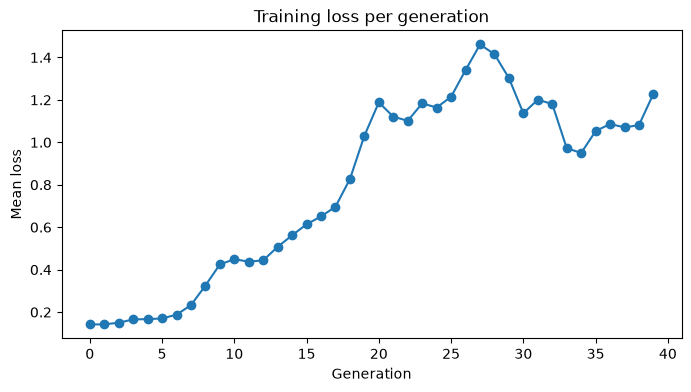

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gens, metrics["loss"], marker="o")
ax.set(xlabel="Generation", ylabel="Mean loss", title="Training loss per generation")
save(fig, "loss.png")

**Average reward.** Both lines should climb as the agent learns to make it further down the corridor. Blue shows AgileRL's evaluation during training. Orange shows our evaluation on the outro scenario, with the shaded band representing one standard deviation.

The band is wide because episodes can end very differently: an early death, a partial trip down the hall, or a vest pickup worth about +10 after scaling. One of those in a handful of episodes moves the average a lot. Compare checkpoints within the same line, since the two lines use different scenarios and different numbers of episodes.

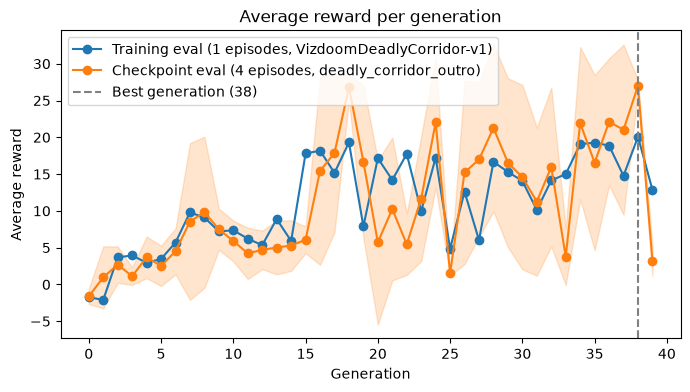

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gens, metrics["eval_fitness"], marker="o", label=f"Training eval ({INIT_HP['EVAL_LOOP']} episodes, {ENV_NAME})")
(line,) = ax.plot(gens, metrics["ckpt_eval_mean"], marker="o", label=f"Checkpoint eval ({EVAL_EPISODES} episodes, {SCENARIO_NAME})")
ax.fill_between(gens, metrics["ckpt_eval_mean"] - metrics["ckpt_eval_std"],
                metrics["ckpt_eval_mean"] + metrics["ckpt_eval_std"], color=line.get_color(), alpha=0.2)
ax.axvline(best_gen, color="gray", linestyle="--", label=f"Best generation ({best_gen})")
ax.set(xlabel="Generation", ylabel="Average reward", title="Average reward per generation")
ax.legend()
save(fig, "average_reward.png")

# Recording
To record the trained agent, we save ViZDoom's `.lmp` demos—which store only the inputs—and then replay them at 720p.


The Gymnasium wrapper doesn't expose demo recording, so `reset_with_lmp` temporarily replaces the reset function with one that starts a recording. `flush_lmp` begins the next episode so the file is actually written.

One gotcha: ViZDoom hangs if the demo path is longer than about 112 characters. We pass a path relative to the working directory, which keeps it short locally. Paths are longer on Colab when using Drive, so recording the best model still works, but `RECORD_CHECKPOINTS = "all"` can hang. Set `USE_DRIVE = False` if you want a video of every generation on Colab.

In [26]:
def reset_with_lmp(env, lmp_path):
    base = env.unwrapped
    orig_reset = base.reset

    def recorded_reset(*, seed=None, options=None):
        gymnasium.Env.reset(base, seed=seed)
        game_seed = int(
            base.np_random.integers(0, np.iinfo(np.uint32).max + 1, dtype=np.uint32)
        )
        base.game.set_seed(game_seed)
        if not base.game.is_running():
            base.game.init()
        # ViZDoom hangs if the demo path is longer than ~112 characters, so pass it relative to the working directory
        base.game.new_episode(os.path.relpath(lmp_path))
        base.state = base.game.get_state()
        return base._VizdoomEnv__collect_observations(), {}

    base.reset = recorded_reset
    try:
        return env.reset()
    finally:
        base.reset = orig_reset


def flush_lmp(env):
    env.unwrapped.game.new_episode()

We record `RECORD_EPISODES` episodes with the best checkpoint, or with every checkpoint when `RECORD_CHECKPOINTS` is set to `"all"`. Best-model videos go in `artifacts/video`; all others remain in the run folder. Existing best-model videos are cleared first so they don't get mixed with the current run.

In [27]:
assert RECORD_CHECKPOINTS in ("best", "all")
record_checkpoints = [best_checkpoint] if RECORD_CHECKPOINTS == "best" else checkpoints

for old in video_dir.glob("best_episode_*"):
    old.unlink()

In [28]:
record_env = make_env(scenario_cfg)
lmps = []
lmp_rewards = {}
for ckpt in record_checkpoints:
    gen = checkpoints.index(ckpt)
    out_dir, prefix = (video_dir, "best") if ckpt == best_checkpoint else (recording_dir, f"gen_{gen}")
    agent = load_agent(ckpt)
    for episode in range(RECORD_EPISODES):
        lmp = out_dir / f"{prefix}_episode_{episode}.lmp"
        obs, _ = reset_with_lmp(record_env, lmp)
        reward, _ = play(record_env, agent, obs)
        print(f"gen {gen:>2}  episode {episode}  reward={reward:.2f}  -> {lmp.name}")
        lmps.append(lmp)
        lmp_rewards[lmp] = reward
flush_lmp(record_env)
record_env.close()

gen 38  episode 0  reward=28.20  -> best_episode_0.lmp
gen 38  episode 1  reward=26.66  -> best_episode_1.lmp
gen 38  episode 2  reward=27.66  -> best_episode_2.lmp


`lmp_to_mp4` replays each demo at 720p with the HUD enabled. The result looks much better than the 84x84 input used for training because we're replaying the actions in a fresh game rather than saving what the network saw. CRF 18, tuned for Doom's flat textures, keeps the files small enough for GitHub. Audio capture is silent on my Mac, so locally generated videos have no sound. Encoding takes a while because the encoder is configured to prioritize compression quality over speed.

In [29]:
SAMPLE_RATE = 22050
VIDEO_PARAMS = dict(  # x264 at constant quality: CRF 18 is visually lossless, and "animation" suits Doom's flat textures
    fps=35, codec="libx264", quality=None, macro_block_size=8,
    ffmpeg_params=["-crf", "18", "-preset", "veryslow", "-tune", "animation", "-movflags", "+faststart"],
)


def lmp_to_mp4(lmp_path):
    """Replay an .lmp at 720p with HUD and audio, and write it next to the .lmp as .mp4."""
    lmp_path = Path(lmp_path)
    mp4_path = lmp_path.with_suffix(".mp4")
    silent_path = lmp_path.with_name(lmp_path.stem + "_silent.mp4")
    wav_path = lmp_path.with_suffix(".wav")

    game = vzd.DoomGame()
    game.load_config(scenario_cfg)
    if DOOM_WAD:
        game.set_doom_game_path(DOOM_WAD)
    game.set_screen_resolution(vzd.ScreenResolution.RES_1280X720)
    game.set_render_hud(True)
    game.set_render_corpses(True)
    game.set_window_visible(False)
    game.set_audio_buffer_enabled(True)
    game.set_audio_sampling_rate(vzd.SamplingRate.SR_22050)
    game.set_audio_buffer_size(1)
    game.add_game_args("+snd_efx 0")
    game.set_mode(vzd.Mode.SPECTATOR)
    game.init()

    frames, audio = [], []
    try:
        game.replay_episode(os.path.relpath(lmp_path))  # relative for the same path length limit as recording
        while not game.is_episode_finished():
            state = game.get_state()
            if state is not None:
                frames.append(np.transpose(state.screen_buffer, (1, 2, 0)))
                if state.audio_buffer is not None:
                    audio.append(state.audio_buffer)
            game.advance_action()
    finally:
        game.close()

    imageio.mimsave(silent_path, frames, **VIDEO_PARAMS)

    audio = np.concatenate(audio) if audio else np.zeros(1)
    if not audio.any():  # no sound captured (e.g. on macOS): keep the silent video
        silent_path.replace(mp4_path)
        return mp4_path

    wavfile.write(wav_path, SAMPLE_RATE, audio)
    subprocess.run(
        [imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-i", silent_path, "-i", wav_path,
         "-c:v", "copy", "-c:a", "aac", "-shortest", mp4_path],
        check=True, capture_output=True,
    )
    silent_path.unlink()
    wav_path.unlink()
    return mp4_path

In [30]:
mp4s = [lmp_to_mp4(lmp) for lmp in lmps]
mp4s

[PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/deadly-corridor-dqn-AgileRL/artifacts/video/best_episode_0.mp4'),
 PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/deadly-corridor-dqn-AgileRL/artifacts/video/best_episode_1.mp4'),
 PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/deadly-corridor-dqn-AgileRL/artifacts/video/best_episode_2.mp4')]

For a quick preview, the highest-scoring episode is converted to a deliberately small GIF that plays directly in the notebook and on GitHub. The full-resolution MP4s remain in `artifacts/video`.

best_episode_0.gif  reward=28.20  (1.4 MB)


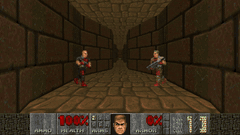

In [31]:
GIF_WIDTH = 240
GIF_FPS = 10


def mp4_to_gif(mp4_path):
    """Write a small GIF next to an MP4, with a palette built from the video so the colors hold up."""
    gif_path = Path(mp4_path).with_suffix(".gif")
    vf = (
        f"fps={GIF_FPS},scale={GIF_WIDTH}:-1:flags=lanczos,split[a][b];"
        "[a]palettegen=max_colors=128:stats_mode=diff[p];[b][p]paletteuse=dither=bayer:bayer_scale=5:diff_mode=rectangle"
    )
    subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-i", mp4_path, "-vf", vf, gif_path], check=True, capture_output=True)
    return gif_path


best_mp4 = max(
    (m for m in mp4s if m.name.startswith("best")),
    key=lambda m: lmp_rewards[m.with_suffix(".lmp")],
)
best_gif = mp4_to_gif(best_mp4)
print(f"{best_gif.name}  reward={lmp_rewards[best_mp4.with_suffix('.lmp')]:.2f}  ({best_gif.stat().st_size / 2**20:.1f} MB)")
display(Image(filename=str(best_gif)))

# Results
A short summary of the run, also saved to `artifacts/results.json` so runs are easy to compare later.

In [32]:
results = {
    "run": run_dir.name,
    "scenario": SCENARIO_NAME,
    "iwad": IWAD_NAME,
    "best_checkpoint": best_checkpoint.name,
    "best_generation": best_gen,
    "best_steps": int(metrics.loc[best_gen, "steps"]),
    "generations": len(checkpoints),
    "checkpoint_eval_mean": round(float(metrics.loc[best_gen, "ckpt_eval_mean"]), 4),
    "checkpoint_eval_std": round(float(metrics.loc[best_gen, "ckpt_eval_std"]), 4),
    "checkpoint_eval_rewards": [round(float(r), 4) for r in eval_rewards[best_gen]],
    "best_video": [str(m.relative_to(experiment_dir)) for m in mp4s if m.name.startswith("best")],
    "best_gif": str(best_gif.relative_to(experiment_dir)),
}
results_path.write_text(json.dumps(results, indent=2))
pd.Series(results, name="value").to_frame()

,value
run,run-20261020_162823
scenario,deadly_corridor_outro
iwad,DOOM2.WAD
best_checkpoint,DQN_0_1950000.pt
best_generation,38
best_steps,1950000
generations,40
checkpoint_eval_mean,26.9801
checkpoint_eval_std,0.7641
checkpoint_eval_rewards,"[26.1154, 28.1996, 26.6653, 26.94]"


# Wrapping Up
Deadly Corridor is a lot harder than Basic: more actions, longer episodes, and enemies that shoot back. Getting to the end of the hallway is no mean feat, and with just a bit of training our agent did it! While we did get success there's still room to push further with different techniques like RainbowDQN. Perhaps we can return to this experiment and optimize our agent to beat it without wasting shots, or taking less damage. But for now I'm happy to have made it this far!

Happy Coding!